# Interpretable Ransomware-Induced Hospital Operational Disruption Severity Model

**Final verified thesis modeling notebook**

This notebook reconstructs the model directly from the uploaded THREAT ransomware dataset and the 2024 Medicare hospital provider dataset.

### Research objective
Develop an interpretable model for estimating documented hospital operational disruption severity associated with ransomware incidents.

### Important limitation
The ransomware incidents occurred during **2016–2021**, while the available Medicare hospital characteristics are from **2024**. Therefore, this analysis is an **interpretable proof-of-concept / associational severity-estimation model**, not a historically aligned prospective prediction model.

No synthetic observations are used in this primary model.


## 1. Libraries and reproducibility

The evaluation uses repeated **StratifiedGroupKFold** cross-validation. Grouping by `threat_id` prevents hospitals belonging to the same ransomware event from appearing in both training and test data.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_SEED = 42


## 2. Load the raw datasets

Place these two files in the same folder as this notebook:

- `threat_database(2).csv`
- `Medicare_IP_Hospitals_by_Provider_2024(1).csv`


In [5]:
THREAT_FILE = "threat_database.csv"
MEDICARE_FILE = "Medicare_IP_Hospitals_by_Provider_2024.csv"

threat = pd.read_csv(THREAT_FILE)
medicare = pd.read_csv(MEDICARE_FILE)

print("THREAT shape:", threat.shape)
print("Medicare shape:", medicare.shape)


THREAT shape: (4349, 14)
Medicare shape: (3044, 57)


## 3. Normalize the CMS Certification Number (CCN) and merge

The THREAT field `medicare_id` and Medicare field `Rndrng_Prvdr_CCN` are normalized to six-character CCNs before merging.

The merge is validated as **many THREAT rows to one Medicare hospital row**.


In [6]:
def normalize_ccn(series):
    return (
        pd.to_numeric(series, errors="coerce")
        .astype("Int64")
        .astype("string")
        .str.zfill(6)
    )

threat["CCN"] = normalize_ccn(threat["medicare_id"])
medicare["CCN"] = normalize_ccn(medicare["Rndrng_Prvdr_CCN"])

medicare_small = medicare[
    [
        "CCN",
        "Rndrng_Prvdr_Org_Name",
        "Tot_Dschrgs",
        "Tot_Cvrd_Days",
        "Bene_Avg_Risk_Scre"
    ]
].copy()

merged = threat.merge(
    medicare_small,
    on="CCN",
    how="left",
    validate="many_to_one",
    indicator=True
)

print(merged["_merge"].value_counts())


_merge
both          2803
left_only     1546
right_only       0
Name: count, dtype: int64


## 4. Keep matched attacked hospitals and audit duplicate hospital–attack pairs

Only THREAT rows representing attacked hospitals with a Medicare match are retained.

Repeated records for the same `CCN + threat_id` are checked before deduplication. In the verified raw-data run, duplicated pairs did **not** contain contradictory `er_diversion` or `cancel_delay` labels.


In [7]:
attacked = merged[
    (merged["_merge"] == "both") &
    (merged["attacked"] == 1)
].copy()

print("Matched attacked rows before deduplication:", len(attacked))

duplicate_pairs = attacked[
    attacked.duplicated(["CCN", "threat_id"], keep=False)
].sort_values(["CCN", "threat_id"])

conflicts = (
    duplicate_pairs.groupby(["CCN", "threat_id"])
    .agg(
        er_values=("er_diversion", "nunique"),
        cancel_values=("cancel_delay", "nunique")
    )
)

conflicts = conflicts[
    (conflicts["er_values"] > 1) |
    (conflicts["cancel_values"] > 1)
]

print("Duplicate rows involved:", len(duplicate_pairs))
print("Duplicate pairs with contradictory outcome labels:", len(conflicts))

events = attacked.drop_duplicates(["CCN", "threat_id"]).copy()

print("Final hospital-attack observations:", len(events))
print("Unique hospitals:", events["CCN"].nunique())
print("Unique ransomware events:", events["threat_id"].nunique())


Matched attacked rows before deduplication: 142
Duplicate rows involved: 20
Duplicate pairs with contradictory outcome labels: 0
Final hospital-attack observations: 131
Unique hospitals: 130
Unique ransomware events: 64


## 5. Construct the target: Operational Disruption Severity

The target is deliberately called **Operational Disruption Severity**, not overall ransomware severity.

It is defined using two documented disruption indicators:

- `er_diversion`
- `cancel_delay`

\[
severity = er\_diversion + cancel\_delay
\]

Therefore:

- **0 = Low:** neither disruption documented
- **1 = Moderate:** one disruption documented
- **2 = High:** both disruptions documented

Because these two variables construct the target, they are **never used as predictors**.


In [8]:
events["disruption_severity"] = (
    events["er_diversion"].astype(int) +
    events["cancel_delay"].astype(int)
)

severity_counts = (
    events["disruption_severity"]
    .value_counts()
    .sort_index()
)

severity_counts.index = ["Low (0)", "Moderate (1)", "High (2)"]
print(severity_counts)


Low (0)         55
Moderate (1)    46
High (2)        30
Name: count, dtype: int64


## 6. Feature engineering and final predictors

Average length of stay is calculated as covered days divided by discharges.

The final model deliberately uses only three hospital-characteristic predictors:

1. `Tot_Dschrgs` — hospital activity/volume proxy
2. `Bene_Avg_Risk_Scre` — Medicare beneficiary risk/case-complexity proxy
3. `avg_length_of_stay` — utilization/operational proxy

Variables such as `Tot_Benes` and `Tot_Cvrd_Days` are not added as separate predictors because earlier auditing showed severe redundancy with hospital volume. Identifiers, matching/design variables, and the two target components are also excluded.


In [9]:
events["avg_length_of_stay"] = (
    events["Tot_Cvrd_Days"] /
    events["Tot_Dschrgs"]
)
events.replace([np.inf, -np.inf], np.nan, inplace=True)

FEATURES = [
    "Tot_Dschrgs",
    "Bene_Avg_Risk_Scre",
    "avg_length_of_stay"
]

X = events[FEATURES].copy()
y = events["disruption_severity"].astype(int)
groups = events["threat_id"]

print("Model observations:", len(X))
print("\nMissing values:")
print(X.isna().sum())


Model observations: 131

Missing values:
Tot_Dschrgs           0
Bene_Avg_Risk_Scre    0
avg_length_of_stay    0
dtype: int64


## 7. Models

Three models are compared:

- **DummyClassifier** — baseline
- **Multinomial Logistic Regression** — primary interpretable model
- **Shallow Decision Tree** — interpretable nonlinear comparator

Class weighting is used for the two fitted classifiers because the three severity classes are unequal.


In [10]:
models = {
    "Baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_SEED
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=3,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=RANDOM_SEED
        ))
    ])
}


## 8. Repeated grouped cross-validation

A single grouped split can be unstable with only **64 independent ransomware events**. To avoid selecting one favorable split, the final evaluation repeats stratified grouped 5-fold CV using **10 fixed random seeds**.

This produces **50 test folds per model**.

Primary metrics:

- **Balanced Accuracy**
- **Macro F1**

These are preferred over ordinary accuracy because the target classes are imbalanced.


In [11]:
fold_rows = []

for seed in range(10):
    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    for model_name, model in models.items():
        for fold, (train_idx, test_idx) in enumerate(
            cv.split(X, y, groups),
            start=1
        ):
            model.fit(X.iloc[train_idx], y.iloc[train_idx])
            pred = model.predict(X.iloc[test_idx])

            fold_rows.append({
                "seed": seed,
                "model": model_name,
                "fold": fold,
                "train_n": len(train_idx),
                "test_n": len(test_idx),
                "test_attack_groups": groups.iloc[test_idx].nunique(),
                "balanced_accuracy": balanced_accuracy_score(
                    y.iloc[test_idx], pred
                ),
                "macro_f1": f1_score(
                    y.iloc[test_idx],
                    pred,
                    average="macro",
                    zero_division=0
                )
            })

fold_results = pd.DataFrame(fold_rows)

summary = (
    fold_results.groupby("model")
    .agg(
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_sd=("balanced_accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_sd=("macro_f1", "std")
    )
    .reset_index()
)

summary


,model,balanced_accuracy_mean,balanced_accuracy_sd,macro_f1_mean,macro_f1_sd
0,Baseline,0.333333,0.00000,0.202032,0.028546
1,Decision Tree,0.351545,0.10849,0.312135,0.091540
2,Logistic Regression,0.378527,0.10426,0.330385,0.075816


### Verified model-comparison result

Across 50 grouped test folds:

| Model | Balanced Accuracy (mean ± SD) | Macro F1 (mean ± SD) |
|---|---:|---:|
| Baseline | 0.333 ± 0.000 | 0.202 ± 0.029 |
| Decision Tree | 0.352 ± 0.108 | 0.312 ± 0.092 |
| Logistic Regression | **0.379 ± 0.104** | **0.330 ± 0.076** |

Logistic Regression performs best on average among these interpretable candidates, but its performance is only modestly above the baseline and varies across grouped folds. The evidence therefore supports **limited predictive signal**, not a high-accuracy prediction system.


## 9. Fixed seed-42 grouped out-of-fold predictions

The repeated-CV averages above are the primary performance result.

For a concrete, auditable confusion matrix and class-level report, the following cell performs one fixed 5-fold `StratifiedGroupKFold` run using random seed 42 and generates exactly one out-of-fold prediction for every observation.


In [12]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

logistic = models["Logistic Regression"]
oof_pred = np.full(len(y), -1, dtype=int)

for train_idx, test_idx in cv.split(X, y, groups):
    logistic.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_pred[test_idx] = logistic.predict(X.iloc[test_idx])

cm = confusion_matrix(y, oof_pred, labels=[0, 1, 2])

cm_df = pd.DataFrame(
    cm,
    index=["Actual Low", "Actual Moderate", "Actual High"],
    columns=["Predicted Low", "Predicted Moderate", "Predicted High"]
)

print(cm_df)
print("\nPooled balanced accuracy:",
      round(balanced_accuracy_score(y, oof_pred), 6))
print("Pooled macro F1:",
      round(f1_score(y, oof_pred, average="macro"), 6))


                 Predicted Low  Predicted Moderate  Predicted High
Actual Low                  27                   9              19
Actual Moderate             15                  13              18
Actual High                 12                   7              11

Pooled balanced accuracy: 0.380061
Pooled macro F1: 0.37471


In [13]:
print(classification_report(
    y,
    oof_pred,
    target_names=["Low", "Moderate", "High"],
    zero_division=0
))


              precision    recall  f1-score   support

         Low       0.50      0.49      0.50        55
    Moderate       0.45      0.28      0.35        46
        High       0.23      0.37      0.28        30

    accuracy                           0.39       131
   macro avg       0.39      0.38      0.37       131
weighted avg       0.42      0.39      0.39       131



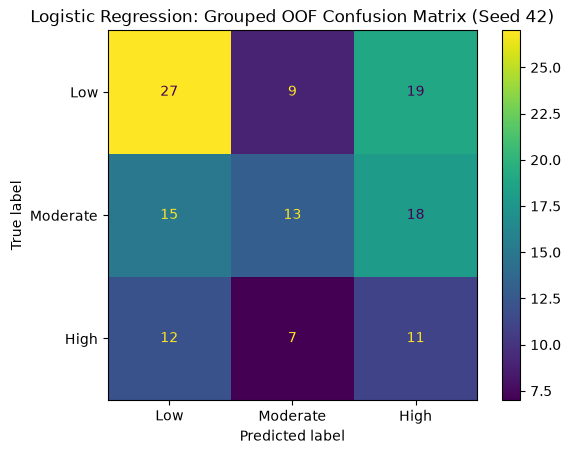

In [14]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Moderate", "High"]
).plot(values_format="d")
plt.title("Logistic Regression: Grouped OOF Confusion Matrix (Seed 42)")
plt.show()


## 10. Logistic Regression interpretation

The model is fitted to the complete dataset **only for descriptive coefficient interpretation after validation**.

Because the Logistic Regression pipeline standardizes predictors, each coefficient represents the change in log-odds associated with a **one-standard-deviation increase** in that predictor for the corresponding class, conditional on the multinomial model.

These coefficients should be interpreted as **associations**, not causal effects.


In [15]:
logistic.fit(X, y)

coef = pd.DataFrame(
    logistic.named_steps["model"].coef_,
    index=["Low", "Moderate", "High"],
    columns=FEATURES
)

coef_long = (
    coef.reset_index(names="class")
    .melt(
        id_vars="class",
        var_name="feature",
        value_name="coefficient"
    )
)

coef_long["odds_ratio_per_1SD"] = np.exp(
    coef_long["coefficient"]
)

coef_long


,class,feature,coefficient,odds_ratio_per_1SD
0,Low,Tot_Dschrgs,-0.346782,0.706959
1,Moderate,Tot_Dschrgs,0.228076,1.256181
2,High,Tot_Dschrgs,0.118706,1.126039
3,Low,Bene_Avg_Risk_Scre,-0.190185,0.826806
4,Moderate,Bene_Avg_Risk_Scre,-0.117722,0.888943
5,High,Bene_Avg_Risk_Scre,0.307907,1.360575
6,Low,avg_length_of_stay,0.236363,1.266633
7,Moderate,avg_length_of_stay,0.062891,1.064911
8,High,avg_length_of_stay,-0.299254,0.741371


## 11. Decision Tree interpretation

The shallow tree is retained as an interpretable nonlinear comparator. Its structure can be inspected after fitting to the complete dataset. This full-data tree is for interpretation; predictive performance is evaluated only through grouped cross-validation.


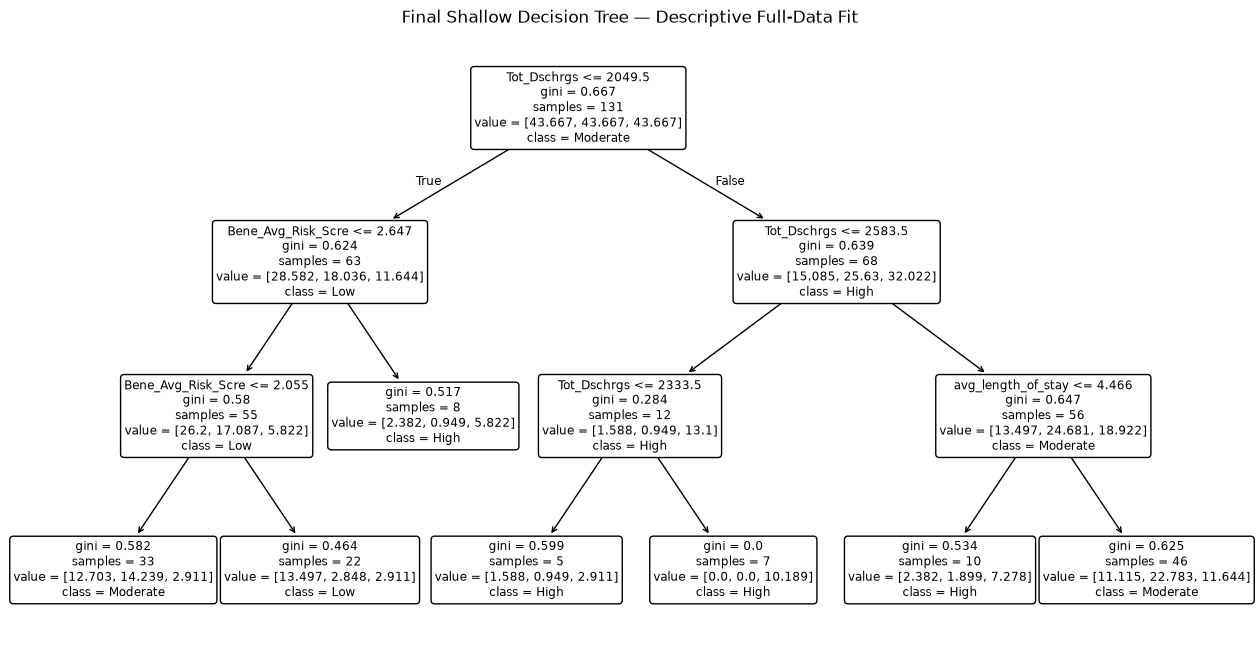

In [16]:
tree_model = models["Decision Tree"]
tree_model.fit(X, y)

plt.figure(figsize=(16, 8))
plot_tree(
    tree_model.named_steps["model"],
    feature_names=FEATURES,
    class_names=["Low", "Moderate", "High"],
    filled=False,
    rounded=True
)
plt.title("Final Shallow Decision Tree — Descriptive Full-Data Fit")
plt.show()


## 12. Save the evidence tables

These exports make the analysis auditable and reusable in the thesis Results chapter.


In [17]:
final_model_data = events[
    [
        "CCN",
        "threat_id",
        "attack_date",
        "er_diversion",
        "cancel_delay",
        "disruption_severity"
    ] + FEATURES
].copy()

final_model_data.to_csv(
    "final_model_data_verified.csv",
    index=False
)
fold_results.to_csv(
    "repeated_grouped_cv_all_folds.csv",
    index=False
)
summary.to_csv(
    "repeated_grouped_cv_summary.csv",
    index=False
)
cm_df.to_csv(
    "logistic_oof_confusion_matrix_seed42.csv"
)
coef_long.to_csv(
    "logistic_standardized_coefficients.csv",
    index=False
)

print("Saved final evidence files.")


Saved final evidence files.


# Final interpretation for the thesis

The primary interpretable Logistic Regression achieved a mean **balanced accuracy of 0.379 (SD 0.104)** and mean **macro-F1 of 0.330 (SD 0.076)** across 50 grouped test folds. It outperformed the most-frequent baseline on both metrics and performed better on average than the shallow Decision Tree.

However, the absolute predictive performance is modest. The result should therefore be interpreted as evidence that the selected hospital-level characteristics contain **limited information for distinguishing documented ransomware-related operational disruption severity**, rather than evidence of a high-performing predictive system.

## Methodological strengths

- Real documented ransomware incidents are used.
- No synthetic observations are used in the primary model.
- Target leakage variables are excluded.
- Hospitals from the same ransomware event are grouped during validation.
- Multiple grouped splits are used rather than selecting a favorable single split.
- The final models are intentionally interpretable.

## Principal limitation

The hospital characteristics are taken from the available **2024 Medicare provider dataset**, whereas ransomware incidents occurred during **2016–2021**. This temporal mismatch limits prospective/historical interpretation. Future work should link each attack to hospital characteristics measured at or before the attack year.

The current analysis should consequently be described as an **interpretable proof-of-concept / associational operational-disruption severity estimation model**.
